In [2]:
# --- Instalasi Library ---
!apt-get update
!apt-get install -y chromium-browser chromium-chromedriver
!pip install selenium beautifulsoup4 pandas tqdm lxml openpyxl

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:4 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [1,799 kB]
Hit:6 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:7 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:8 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:9 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,751 kB]
Get:10 http://security.ubuntu.com/ubuntu jammy-security/universe amd64 Packages [1,253 kB]
Get:11 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [9,063 kB]
Get:12 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [3,036

##SCRAPING DATA


In [3]:
#  Scraping Hotel Swiss-Belinn Manyar ---
import time
import pandas as pd
from tqdm.notebook import tqdm
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.common.exceptions import TimeoutException, NoSuchElementException
from bs4 import BeautifulSoup

# --- 1. SETUP BROWSER ---
print("Memulai Inisialisasi WebDriver...")
options = webdriver.ChromeOptions()
options.add_argument('--headless')
options.add_argument('--no-sandbox')
options.add_argument('--disable-dev-shm-usage')
user_agent = 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/125.0.0.0 Safari/537.36'
options.add_argument(f'user-agent={user_agent}')
options.add_experimental_option("excludeSwitches", ["enable-automation"])
options.add_experimental_option('useAutomationExtension', False)
browser = webdriver.Chrome(options=options)
print("WebDriver berhasil diinisialisasi.")

try:

    URL = "https://www.traveloka.com/id-id/hotel/indonesia/swiss-belinn-manyar-surabaya-546016"

    browser.get(URL)
    browser.maximize_window()
    print(f"Halaman utama untuk Swiss-Belinn Manyar berhasil dibuka. Menunggu...")

    WebDriverWait(browser, 20).until(EC.presence_of_element_located((By.ID, "accom-detail-navigation-bar")))
    time.sleep(3)

    try:
        print("Mencari dan mengklik tab 'Review'...")
        review_tab_selector = (By.XPATH, "//div[@data-testid='link-REVIEW']")
        review_tab = WebDriverWait(browser, 10).until(EC.element_to_be_clickable(review_tab_selector))
        browser.execute_script("arguments[0].click();", review_tab)
        print("Berhasil mengklik tab 'Review'. Menunggu halaman ulasan memuat...")
        time.sleep(5)
    except Exception as e:
        print(f"Gagal mengklik tab 'Review'. Error: {e}")
        raise

    # --- LOGIKA PAGINASI ---
    data = []
    page_count = 1
    target_reviews = 1000
    pbar = tqdm(total=target_reviews, desc="Mengambil Ulasan")

    while len(data) < target_reviews:
        print(f"\n--- Memulai Scraping Halaman {page_count} ---")
        try:
            WebDriverWait(browser, 20).until(EC.presence_of_element_located((By.XPATH, "//div[@data-testid='review-list-container']")))
            time.sleep(2)

            soup = BeautifulSoup(browser.page_source, 'lxml')
            review_cards = soup.find_all('div', class_='css-1dbjc4n r-14lw9ot r-h1746q r-kdyh1x r-d045u9 r-1udh08x r-d23pfw')

            if not review_cards:
                print("Tidak ada ulasan baru yang ditemukan. Mungkin akhir dari halaman.")
                break

            for card in review_cards:
                rating_element = card.find('div', attrs={'data-testid': 'tvat-ratingScore'})
                review_text_element = card.find('div', class_='css-cens5h')

                if review_text_element and rating_element:
                    rating = rating_element.text.strip().replace(',', '.')
                    review_text = review_text_element.text.strip()

                    data.append({'Rating': float(rating), 'Ulasan': review_text})
                    pbar.update(1)

                if len(data) >= target_reviews: break

            if len(data) >= target_reviews:
                print(f"Target {target_reviews} ulasan tercapai.")
                break

            next_page_button = WebDriverWait(browser, 10).until(EC.element_to_be_clickable((By.XPATH, '//div[@data-testid="next-page-btn"]')))

            if next_page_button.get_attribute('aria-disabled') == 'true':
                print("Tombol 'Next Page' tidak aktif. Scraping selesai.")
                break
            else:
                browser.execute_script("arguments[0].click();", next_page_button)
                page_count += 1

        except (TimeoutException, NoSuchElementException):
            print("Tidak dapat menemukan kontainer review atau tombol 'Next'. Berhenti.")
            break
        except Exception as e:
            print(f"Terjadi kesalahan tak terduga: {e}")
            break

finally:
    pbar.close()
    if 'browser' in locals() and browser.service.is_connectable():
        browser.quit()

    if data:
        df = pd.DataFrame(data)
        file_name_csv = "review_swissbelinn_manyar.csv"
        df.to_csv(file_name_csv, index=False)
        print(f"\n--- PROSES SCRAPING SELESAI ---")
        print(f"Total ulasan berhasil di-scrape: {len(df)}")
        print(f"✅ Data berhasil disimpan ke file '{file_name_csv}'")
    else:
        print("\nTidak ada data yang berhasil di-scrape.")

Memulai Inisialisasi WebDriver...
WebDriver berhasil diinisialisasi.
Halaman utama untuk Swiss-Belinn Manyar berhasil dibuka. Menunggu...
Mencari dan mengklik tab 'Review'...
Berhasil mengklik tab 'Review'. Menunggu halaman ulasan memuat...


Mengambil Ulasan:   0%|          | 0/1000 [00:00<?, ?it/s]


--- Memulai Scraping Halaman 1 ---

--- Memulai Scraping Halaman 2 ---

--- Memulai Scraping Halaman 3 ---

--- Memulai Scraping Halaman 4 ---

--- Memulai Scraping Halaman 5 ---

--- Memulai Scraping Halaman 6 ---

--- Memulai Scraping Halaman 7 ---

--- Memulai Scraping Halaman 8 ---

--- Memulai Scraping Halaman 9 ---

--- Memulai Scraping Halaman 10 ---

--- Memulai Scraping Halaman 11 ---

--- Memulai Scraping Halaman 12 ---

--- Memulai Scraping Halaman 13 ---

--- Memulai Scraping Halaman 14 ---

--- Memulai Scraping Halaman 15 ---

--- Memulai Scraping Halaman 16 ---

--- Memulai Scraping Halaman 17 ---

--- Memulai Scraping Halaman 18 ---

--- Memulai Scraping Halaman 19 ---

--- Memulai Scraping Halaman 20 ---

--- Memulai Scraping Halaman 21 ---

--- Memulai Scraping Halaman 22 ---

--- Memulai Scraping Halaman 23 ---

--- Memulai Scraping Halaman 24 ---

--- Memulai Scraping Halaman 25 ---

--- Memulai Scraping Halaman 26 ---

--- Memulai Scraping Halaman 27 ---

--- Memul

##Pembersihan & Pra-pemrosesan Teks


In [4]:
!pip install sastrawi

import pandas as pd
import re
from tqdm.notebook import tqdm
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

tqdm.pandas()

# Inisialisasi
factory = StemmerFactory()
stemmer = factory.create_stemmer()
stopword_factory = StopWordRemoverFactory()
stopword_remover = stopword_factory.create_stop_word_remover()

# Muat dataset yang baru di-scrape
try:
    # Ganti nama file ini jika Anda menggunakan nama lain
    df = pd.read_csv('review_swissbelinn_manyar.csv')
    print(f"Berhasil memuat 'review_swissbelinn_manyar.csv', ditemukan {len(df)} baris.")
except FileNotFoundError:
    print("File 'review_swissbelinn_manyar.csv' tidak ditemukan. Pastikan script scraping berhasil dijalankan.")
    raise

# Fungsi Preprocessing
normalization_dict = {
    'yg': 'yang', 'ga': 'tidak', 'gak': 'tidak', 'gk': 'tidak', 'tdk': 'tidak',
    'klo': 'kalau', 'utk': 'untuk', 'dg': 'dengan', 'krn': 'karena',
    'kmr': 'kamar', 'kmrnya': 'kamarnya', 'tmpt': 'tempat', 'dkt': 'dekat', 'dgn': 'dengan',
    'fasilitasnya': 'fasilitas', 'pelayanannya': 'pelayanan', 'kebersihannya': 'kebersihan',
    'nyaman': 'nyaman', 'bersih': 'bersih', 'ok': 'bagus', 'oke': 'bagus', 'bgt': 'banget',
    'recomended': 'direkomendasikan', 'rekomended': 'direkomendasikan'
}

def normalize_text(text):
    words = text.split()
    normalized_words = [normalization_dict.get(word, word) for word in words]
    return ' '.join(normalized_words)

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = normalize_text(text)
    text = stopword_remover.remove(text)
    text = stemmer.stem(text)
    text = ' '.join(text.split())
    return text

df['cleaned_review'] = df['Ulasan'].progress_apply(preprocess_text)
df.to_csv('review_swissbelinn_manyar_cleaned.csv', index=False)
print("\nData berhasil dibersihkan dan disimpan ke 'review_swissbelinn_manyar_cleaned.csv'")
print("\nContoh data setelah dibersihkan:")
print(df[['Ulasan', 'cleaned_review']].head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.5 MB/s eta 0:00:00
Berhasil memuat 'review_swissbelinn_manyar.csv', ditemukan 1000 baris.


  0%|          | 0/1000 [00:00<?, ?it/s]


Data berhasil dibersihkan dan disimpan ke 'review_swissbelinn_manyar_cleaned.csv'

Contoh data setelah dibersihkan:
                                              Ulasan  \
0  Hotel nyaman, bersih, dan view-nya bagusss, yipee   
1  tempat sangat strategis, dekat tempat makanan ...   
2      Kamar dan suasana restourant dan hotel nyaman   
3  Staf hotel yang ramah, dan tempat lokasi yang ...   
4  lokasi - sangat strategis, mau cari makan deka...   

                                      cleaned_review  
0          hotel nyaman bersih viewnya bagusss yipee  
1  tempat sangat strategis dekat tempat makan ena...  
2              kamar suasana restourant hotel nyaman  
3    staf hotel ramah tempat lokasi sangat strategis  
4  lokasi sangat strategis mau cari makan dekat s...  


##Analisis Eksplorasi Data (EDA)

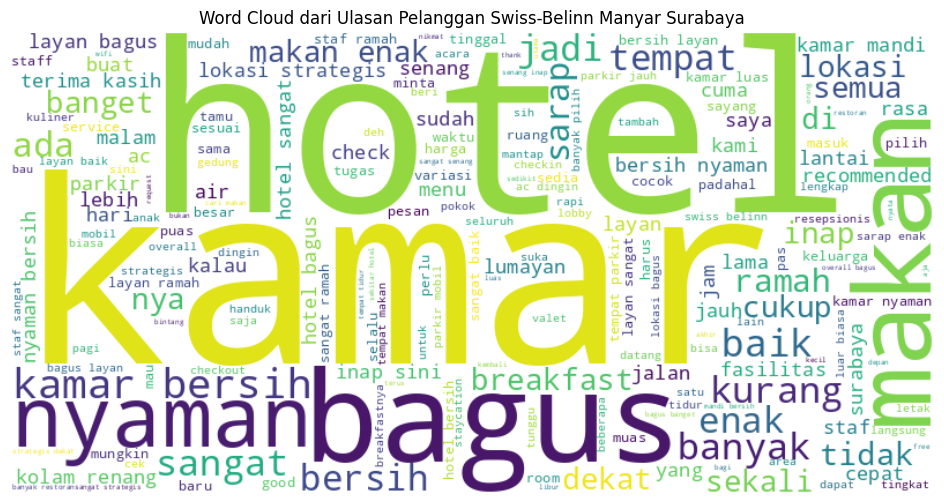

In [5]:
# --- Cell 4: Word Cloud ---
import matplotlib.pyplot as plt
from wordcloud import WordCloud

df_cleaned = pd.read_csv('/content/review_swissbelinn_manyar_cleaned.csv')

all_text = ' '.join(df_cleaned['cleaned_review'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud dari Ulasan Pelanggan Swiss-Belinn Manyar Surabaya')
plt.show()

##Pemodelan Topik


In [28]:
# --- Pemodelan Topik dengan LDA & BERTopic ---
!pip install bertopic==0.15.0 scikit-learn
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from bertopic import BERTopic

docs = df_cleaned['cleaned_review'].dropna().tolist()

# --- Metode 1: LDA ---
print("--- Hasil Pemodelan Topik dengan LDA ---")
vectorizer = CountVectorizer(max_df=0.9, min_df=10)
X = vectorizer.fit_transform(docs)
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

def display_topics(model, feature_names, no_top_words):
    for topic_idx, topic in enumerate(model.components_):
        print(f"LDA Topik {topic_idx+1}: {' | '.join([feature_names[i] for i in topic.argsort()[:-no_top_words - 1:-1]])}")

display_topics(lda, vectorizer.get_feature_names_out(), 10)

# --- Metode 2: BERTopic ---
print("\n--- Hasil Pemodelan Topik dengan BERTopic ---")
topic_model = BERTopic(language="multilingual", verbose=False, min_topic_size=20) # menaikkan min_topic_size
topics, probs = topic_model.fit_transform(docs)

print(topic_model.get_topic_info())

--- Hasil Pemodelan Topik dengan LDA ---
LDA Topik 1: hotel | surabaya | inap | dekat | sangat | bersih | nya | banyak | sini | check
LDA Topik 2: sangat | layan | baik | ramah | kamar | senang | hotel | kasih | staf | bersih
LDA Topik 3: bagus | kamar | bersih | nyaman | makan | lokasi | hotel | layan | enak | sarap
LDA Topik 4: parkir | hotel | jauh | bagus | mobil | inap | jadi | buat | jalan | cuma
LDA Topik 5: kamar | ac | kurang | mandi | lebih | jam | air | dingin | tidak | lama

--- Hasil Pemodelan Topik dengan BERTopic ---
Mohon tunggu, proses BERTopic sedang berjalan...
    Topic  Count                                 Name  \
0      -1    280          -1_kamar_bagus_bersih_makan   
1       0    200           0_hotel_bagus_sangat_dekat   
2       1     89              1_sarap_inap_baik_layan   
3       2     88            2_parkir_jauh_hotel_mobil   
4       3     49            3_staf_ramah_staff_sangat   
5       4     48                4_mandi_kamar_bau_air   
6       5     

##Analisis Sentimen Berbasis Aspek

Memuat model sentimen publik dari Hugging Face


Device set to use cpu


Model berhasil dimuat.


Menganalisis Sentimen Aspek:   0%|          | 0/1000 [00:00<?, ?it/s]

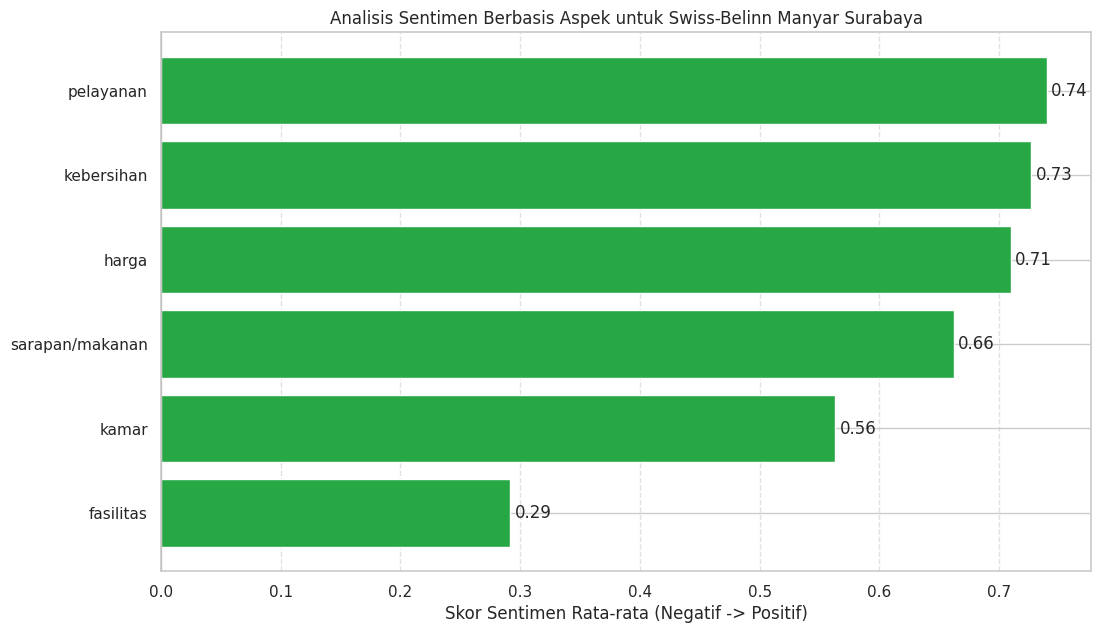

In [32]:
# Instalasi library
!pip install transformers torch sentencepiece

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from transformers import pipeline
import re

# Muat Model Sentiment PUBLIK dari Hugging Face
print("Memuat model sentimen publik dari Hugging Face")

model_name = "ayameRushia/bert-base-indonesian-1.5G-sentiment-analysis-smsa"
try:
    sentiment_analyzer = pipeline("sentiment-analysis", model=model_name)
    print("Model berhasil dimuat.")
except Exception as e:
    print(f"Gagal memuat model. Error: {e}")
    # Jika gagal, hentikan eksekusi sel ini
    raise

# Muat data yang sudah dibersihkan
try:
    df_cleaned = pd.read_csv('review_swissbelinn_manyar_cleaned.csv')
except FileNotFoundError:
    print("File 'review_swissbelinn_manyar_cleaned.csv' tidak ditemukan. Jalankan sel preprocessing terlebih dahulu.")
    raise


# Definisikan Aspek dan Keyword
aspect_keywords = {
    'kebersihan': ['bersih', 'rapi', 'wangi', 'kotor', 'debu', 'bau'],
    'pelayanan': ['layan', 'staf', 'ramah', 'cepat', 'bantu', 'sopan', 'judes', 'lambat', 'resepsionis', 'responsif'],
    'kamar': ['kamar', 'ranjang', 'kasur', 'luas', 'sempit', 'ac', 'handuk', 'kedap', 'tv'],
    'sarapan/makanan': ['sarap', 'makan', 'menu', 'rasa', 'enak', 'variasi', 'resto', 'pilih'],
    'fasilitas': ['fasilitas', 'kolam', 'renang', 'gym', 'parkir', 'lengkap', 'wifi', 'lobby'],
    'harga': ['harga', 'mahal', 'murah', 'biaya', 'sesuai', 'worth']
}

# Proses Analisis
aspect_sentiments = {key: [] for key in aspect_keywords.keys()}

for review in tqdm(df_cleaned['Ulasan'].dropna().tolist(), desc="Menganalisis Sentimen Aspek"):
    sentences = re.split(r'[.!?]', review)
    sentences = [s.strip() for s in sentences if s]

    for aspect, keywords in aspect_keywords.items():
        found_in_review = False
        for sentence in sentences:
            if any(keyword in sentence.lower() for keyword in keywords):
                try:
                    result = sentiment_analyzer(sentence)
                    label = result[0]['label']

                    if label.lower() == 'positive':
                        aspect_sentiments[aspect].append(1)
                    elif label.lower() == 'negative':
                        aspect_sentiments[aspect].append(-1)

                    found_in_review = True
                    break # Lanjut ke aspek berikutnya setelah kalimat relevan pertama ditemukan
                except Exception as e:
                    # Lewati kalimat yang terlalu panjang atau bermasalah untuk dianalisis
                    pass
        if found_in_review:
            continue

# Agregasi dan Visualisasi
avg_sentiments = {aspect: (sum(scores) / len(scores) if scores else 0) for aspect, scores in aspect_sentiments.items()}
df_sentiment = pd.DataFrame(list(avg_sentiments.items()), columns=['Aspek', 'Skor Sentimen Rata-rata']).sort_values('Skor Sentimen Rata-rata')

plt.figure(figsize=(12, 7))
bars = plt.barh(df_sentiment['Aspek'], df_sentiment['Skor Sentimen Rata-rata'], color=df_sentiment['Skor Sentimen Rata-rata'].apply(lambda x: '#28a745' if x > 0.1 else ('#ffc107' if x >= -0.1 else '#dc3545')))
plt.xlabel('Skor Sentimen Rata-rata (Negatif -> Positif)')
plt.title('Analisis Sentimen Berbasis Aspek untuk Swiss-Belinn Manyar Surabaya')
plt.axvline(0, color='grey', linewidth=0.8)
plt.bar_label(bars, fmt='%.2f', padding=3)
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

##Visualisasi

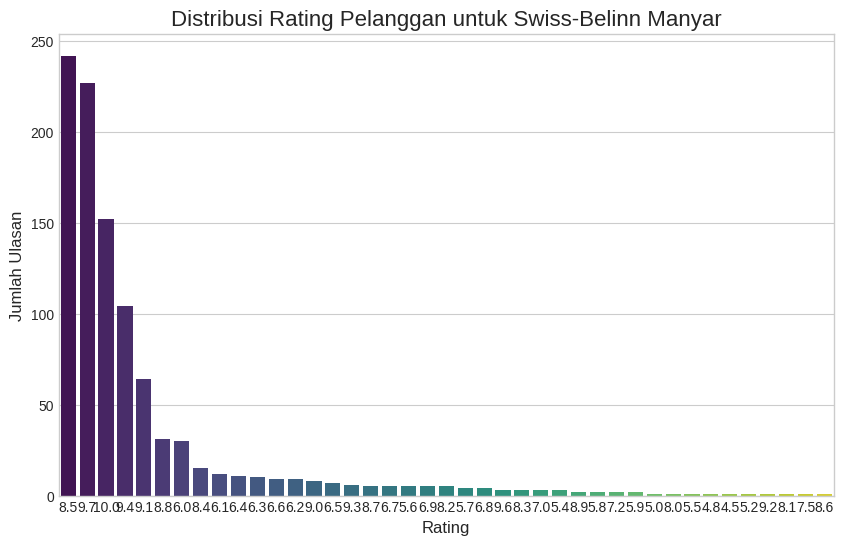

In [8]:
# ---Visualisasi Distribusi Rating ---
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))

# Menggunakan seaborn untuk membuat count plot (histogram untuk data kategorikal/diskrit)
sns.countplot(x='Rating', data=df_cleaned, palette='viridis', order=df_cleaned['Rating'].value_counts().index)

plt.title('Distribusi Rating Pelanggan untuk Swiss-Belinn Manyar', fontsize=16)
plt.xlabel('Rating', fontsize=12)
plt.ylabel('Jumlah Ulasan', fontsize=12)
plt.show()

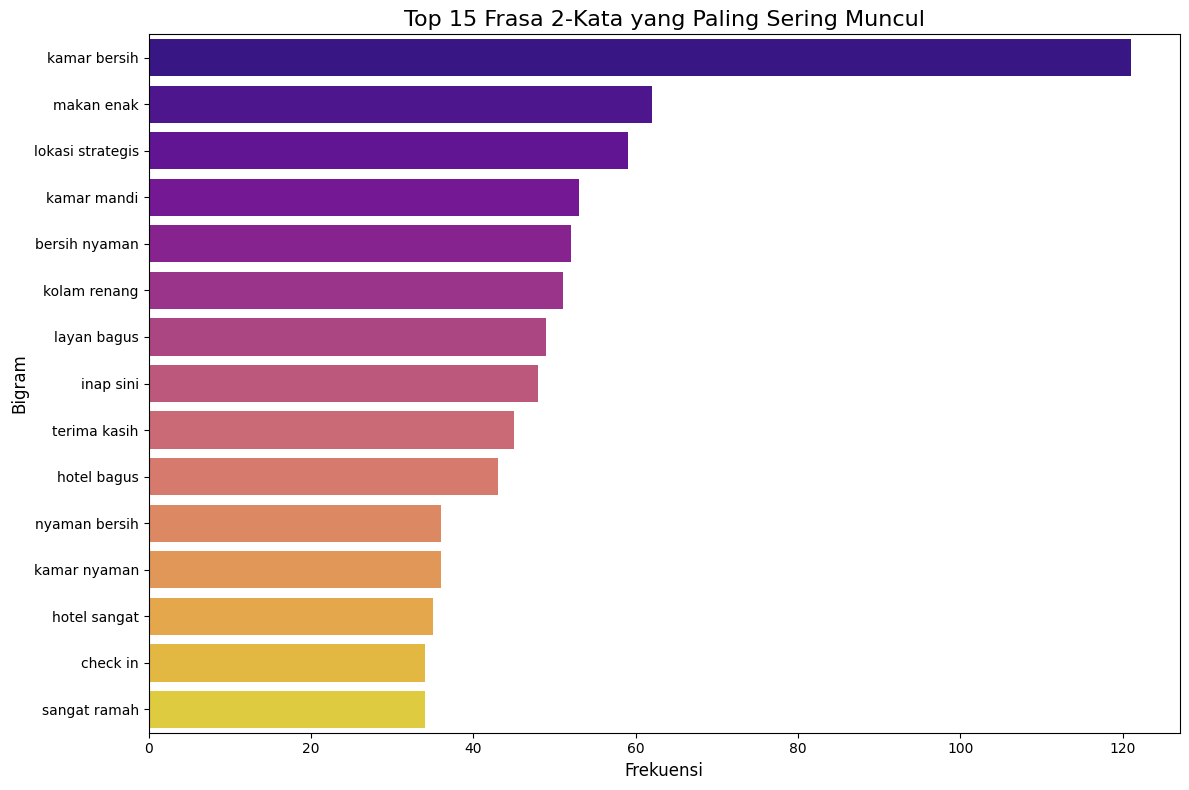

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# --- persiapan data
def get_top_n_grams(corpus, ngram_range, n=15):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words=None).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

docs = df_cleaned['cleaned_review'].dropna()
top_bigrams = get_top_n_grams(docs, ngram_range=(2, 2), n=15)
df_bigram = pd.DataFrame(top_bigrams, columns=['Bigram', 'Frekuensi'])

top_trigrams = get_top_n_grams(docs, ngram_range=(3, 3), n=15)
df_trigram = pd.DataFrame(top_trigrams, columns=['Trigram', 'Frekuensi'])

# Plot 1: Grafik untuk Bigram (Frasa 2 Kata)
plt.figure(figsize=(12, 8))
sns.barplot(x='Frekuensi', y='Bigram', data=df_bigram, palette='plasma')
plt.title('Top 15 Frasa 2-Kata yang Paling Sering Muncul', fontsize=16)
plt.xlabel('Frekuensi', fontsize=12)
plt.ylabel('Bigram', fontsize=12)
plt.tight_layout()
plt.show()



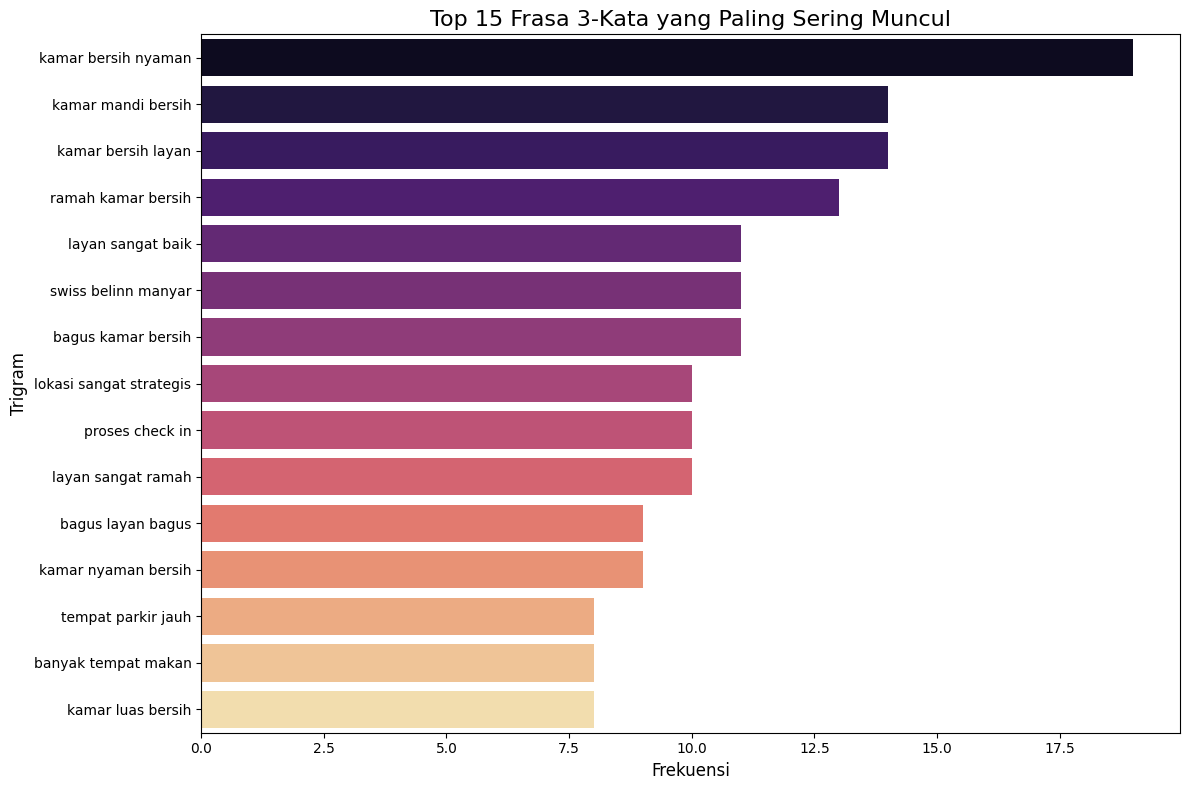

In [12]:
# Plot 2: Grafik untuk Trigram (Frasa 3 Kata)
plt.figure(figsize=(12, 8))
sns.barplot(x='Frekuensi', y='Trigram', data=df_trigram, palette='magma')
plt.title('Top 15 Frasa 3-Kata yang Paling Sering Muncul', fontsize=16)
plt.xlabel('Frekuensi', fontsize=12)
plt.ylabel('Trigram', fontsize=12)
plt.tight_layout()
plt.show()

In [18]:
# --- Menentukan Aspek dan Topik Utama LDA

# Impor library yang dibutuhkan
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

print("--- Memulai Proses Identifikasi Topik Utama LDA ---")

# 2. Persiapan Data dan Pelatihan Model LDA
docs = df_cleaned['cleaned_review'].dropna().tolist()
vectorizer = CountVectorizer(max_df=0.9, min_df=10, stop_words=None)
X = vectorizer.fit_transform(docs)

# Kita tentukan jumlah topik adalah 8 (berdasarkan hasil optimalisasi sebelumnya)
num_topics = 8
lda_model = LatentDirichletAllocation(n_components=num_topics, random_state=100)
lda_model.fit(X)
print(f"✅ Model LDA dengan {num_topics} topik berhasil dilatih.")

# 3. Ekstraksi dan Penamaan Topik (Aspek)
feature_names = vectorizer.get_feature_names_out()
topic_results = []

for topic_idx, topic in enumerate(lda_model.components_):
    # Mengambil 7 kata kunci teratas untuk setiap topik
    top_words = [feature_names[i] for i in topic.argsort()[:-8:-1]]

    # Memberi nama "Aspek" atau "Tema" secara manual berdasarkan interpretasi kata kunci
    # (Ini adalah langkah analisis kualitatif yang penting)
    # Anda bisa menyesuaikan nama-nama ini berdasarkan hasil yang muncul

    # Contoh sederhana penamaan aspek berdasarkan kata kunci yang paling mungkin muncul:
    aspect_name = f"Topik Umum {topic_idx + 1}" # Default name
    if any(word in top_words for word in ['kamar', 'bersih', 'nyaman', 'luas', 'kasur']):
        aspect_name = "Kenyamanan & Kebersihan Kamar"
    elif any(word in top_words for word in ['layan', 'staf', 'ramah', 'bantu', 'check']):
        aspect_name = "Pelayanan Staf & Proses Check-in"
    elif any(word in top_words for word in ['sarap', 'makan', 'menu', 'enak']):
        aspect_name = "Kualitas Sarapan"
    elif any(word in top_words for word in ['lokasi', 'dkt', 'strategis']):
        aspect_name = "Lokasi Hotel"
    elif any(word in top_words for word in ['kolam', 'renang', 'fasilitas']):
        aspect_name = "Fasilitas Hotel"

    topic_results.append({
        "ID Topik": topic_idx + 1,
        "Aspek Utama": aspect_name,
        "Kata Kunci Utama": ", ".join(top_words)
    })

# 4. Tampilkan dalam DataFrame yang rapi
df_topics = pd.DataFrame(topic_results)

print("\n\n--- TABEL ASPEK DAN TOPIK UTAMA DARI MODEL LDA ---")
display(df_topics)

--- Memulai Proses Identifikasi Topik Utama LDA ---
✅ Model LDA dengan 8 topik berhasil dilatih.


--- TABEL ASPEK DAN TOPIK UTAMA DARI MODEL LDA ---


,ID Topik,Aspek Utama,Kata Kunci Utama
0,1,Kenyamanan & Kebersihan Kamar,"kamar, bersih, nyaman, sarap, ramah, hotel, nya"
1,2,Kenyamanan & Kebersihan Kamar,"kolam, renang, kamar, bagus, cukup, bersih, ke..."
2,3,Kenyamanan & Kebersihan Kamar,"kamar, ac, jam, check, dingin, tidak, bed"
3,4,Topik Umum 4,"sangat, inap, kasih, hotel, senang, sini, swiss"
4,5,Pelayanan Staf & Proses Check-in,"hotel, bagus, layan, sangat, baik, sekali, inap"
5,6,Kenyamanan & Kebersihan Kamar,"bagus, hotel, bersih, lokasi, makan, layan, sa..."
6,7,Kenyamanan & Kebersihan Kamar,"kamar, makan, bersih, enak, banyak, inap, mandi"
7,8,Kenyamanan & Kebersihan Kamar,"parkir, jauh, kurang, hotel, mobil, kamar, tempat"



--- Memulai Proses Visualisasi Topik LDA ---


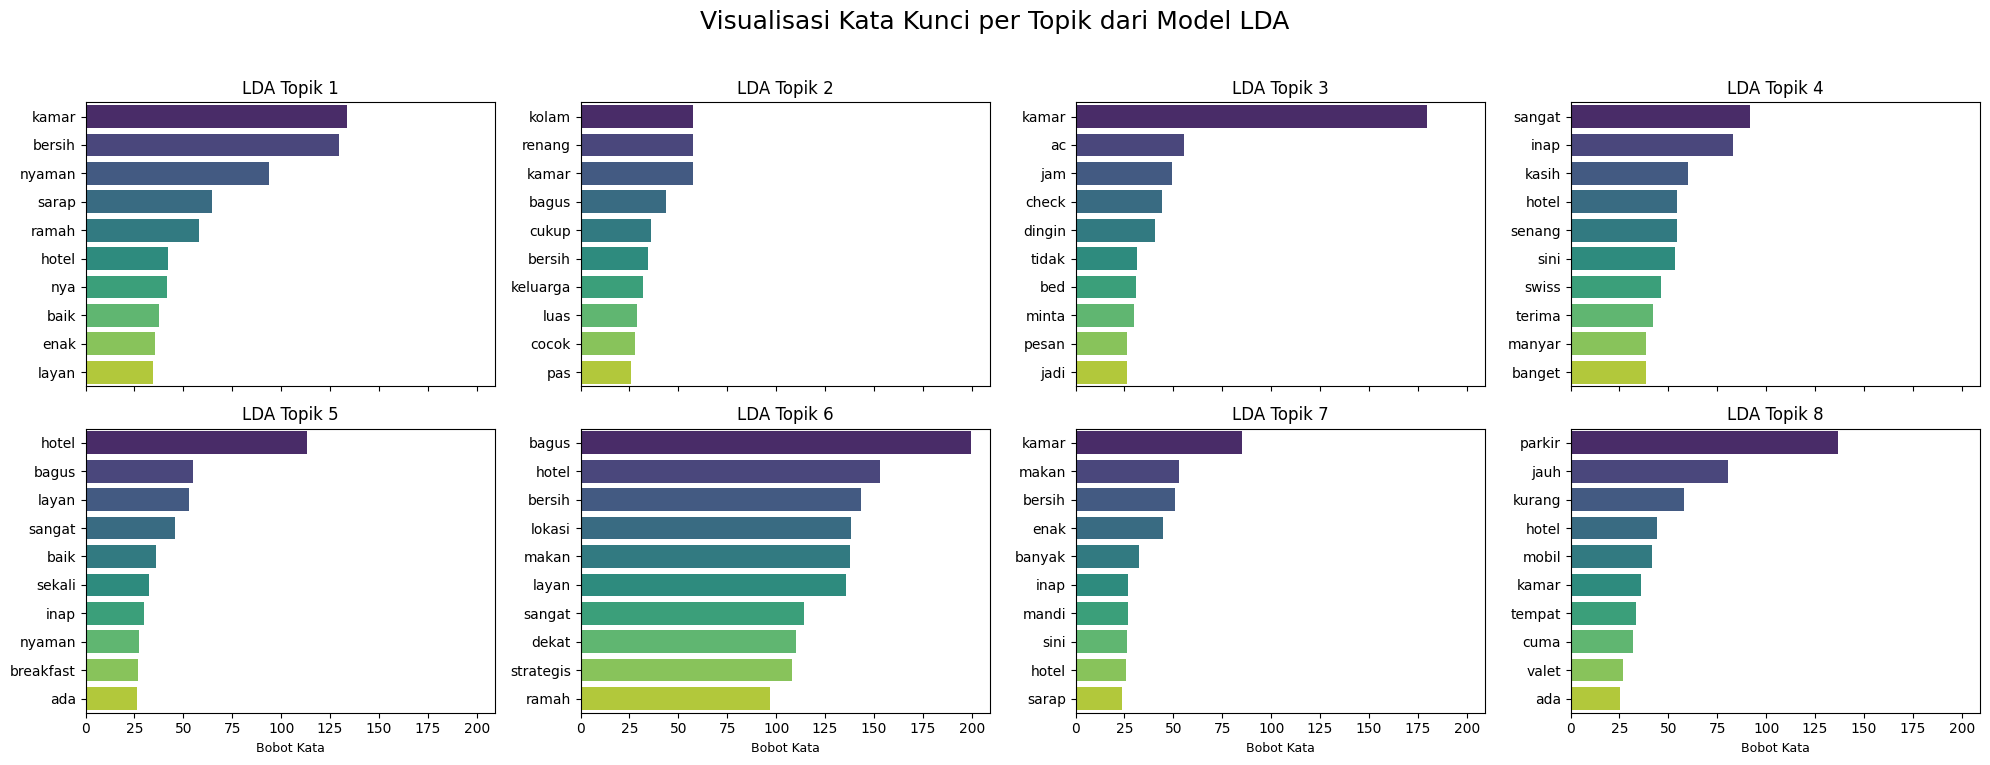

In [19]:
# ---  Visualisasi Topik Utama LDA

# Impor library plotting
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("\n--- Memulai Proses Visualisasi Topik LDA ---")

if 'lda_model' not in locals() or 'vectorizer' not in locals():
    print("Variabel tidak ditemukan, melatih ulang model LDA...")
    # Blok ini hanya akan berjalan jika Anda menjalankan sel ini secara terpisah
    df_cleaned = pd.read_csv('review_swissbelinn_manyar_cleaned.csv')
    docs = df_cleaned['cleaned_review'].dropna().tolist()
    vectorizer = CountVectorizer(max_df=0.9, min_df=10, stop_words=None)
    X = vectorizer.fit_transform(docs)
    lda_model = LatentDirichletAllocation(n_components=8, random_state=100)
    lda_model.fit(X)
    print("✅ Model LDA siap.")

feature_names = vectorizer.get_feature_names_out()
n_top_words = 10
num_topics = lda_model.n_components
rows = int(np.ceil(num_topics / 4))

fig, axes = plt.subplots(rows, 4, figsize=(20, 4 * rows), sharex=True)
axes = axes.flatten()

for topic_idx, topic in enumerate(lda_model.components_):
    top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
    top_features = [feature_names[i] for i in top_features_ind]
    weights = topic[top_features_ind]

    ax = axes[topic_idx]
    sns.barplot(x=weights, y=top_features, ax=ax, palette='viridis')
    ax.set_title(f'LDA Topik {topic_idx + 1}', fontdict={'fontsize': 12})
    ax.set_xlabel('Bobot Kata', fontdict={'fontsize': 9})
    ax.set_ylabel('')

for i in range(num_topics, len(axes)):
    axes[i].axis('off')

plt.suptitle("Visualisasi Kata Kunci per Topik dari Model LDA", fontsize=18)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

##Pelatihan Data


In [35]:
!pip install --upgrade --force-reinstall scipy==1.10.1 gensim


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.9/58.9 kB 3.4 MB/s eta 0:00:00
  Using cached gensim-4.3.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (8.1 kB)
  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.1/34.1 MB 13.9 MB/s eta 0:00:00
Using cached gensim-4.3.3-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (26.7 MB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.2/83.2 kB 6.6 MB/s eta 0:00:00
  Attempting uninstall: wrapt
    Found existing installation: wrapt 1.17.2
    Uninstalling wrapt-1.17.2:
      Successfully uninstalled wrapt-1.17.2
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstall

In [8]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# vectorizer dan data
vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
X = vectorizer.fit_transform([' '.join(doc) for doc in texts])

# latih model LDA
lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

print("Model LDA berhasil dilatih.")

Model LDA berhasil dilatih.


In [6]:
!pip install bertopic -q

from bertopic import BERTopic

docs = [' '.join(doc) for doc in texts]

# Latih BERTopic
topic_model = BERTopic(language="indonesian", verbose=True)
topics, _ = topic_model.fit_transform(docs)

print("Model BERTopic berhasil dilatih.")


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

2025-06-26 14:02:20,015 - BERTopic - Transformed documents to Embeddings
2025-06-26 14:02:22,765 - BERTopic - Reduced dimensionality
2025-06-26 14:02:22,802 - BERTopic - Clustered reduced embeddings


Model BERTopic berhasil dilatih.


##Evaluasi Skor Koherensi

In [9]:
import gensim
from gensim.corpora.dictionary import Dictionary
from gensim.models.coherencemodel import CoherenceModel
import pandas as pd

print("Library Gensim dan SciPy berhasil diinstal.")

# Muat ulang data bersih
try:
    df_cleaned = pd.read_csv('/content/review_swissbelinn_manyar_cleaned.csv')
    texts = df_cleaned['cleaned_review'].dropna().str.split().tolist()
except FileNotFoundError:
    print("File tidak ditemukan. Jalankan preprocessing terlebih dahulu.")
    raise

# Buat Dictionary dan Corpus
dictionary = Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

# Ambil Topik dari LDA dan BERTopic
try:
    lda_topics = []
    feature_names = vectorizer.get_feature_names_out()
    for topic_idx, topic in enumerate(lda.components_):
        lda_topics.append([feature_names[i] for i in topic.argsort()[:-11:-1]])
except NameError:
    print("Variabel 'lda' atau 'vectorizer' tidak ditemukan.")
    lda_topics = None

try:
    bertopic_topics = []
    for i in range(len(topic_model.get_topics()) - 1):
        words = [val[0] for val in topic_model.get_topic(i)]
        bertopic_topics.append(words)
except NameError:
    print("Variabel 'topic_model' tidak ditemukan.")
    bertopic_topics = None

# Hitung Skor Koherensi
if lda_topics:
    coherence_model_lda = CoherenceModel(topics=lda_topics, texts=texts, dictionary=dictionary, coherence='c_v')
    print(f"\nCoherence Score (LDA): {coherence_model_lda.get_coherence():.4f}")

if bertopic_topics:
    coherence_model_bt = CoherenceModel(topics=bertopic_topics, texts=texts, dictionary=dictionary, coherence='c_v')
    print(f"Coherence Score (BERTopic): {coherence_model_bt.get_coherence():.4f}")

Library Gensim dan SciPy berhasil diinstal.

Coherence Score (LDA): 0.5318
Coherence Score (BERTopic): 0.4920
